In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Set random seed for reproducibility
np.random.seed(42)

# Load data
df_raw = pd.read_csv('../01 - DataPreparation/df_prepared.csv')
print(df_raw.columns)


Index(['BGGId', 'GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Rating', 'Age', 'AvgPlaytime', 'AgeRec',
       'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
       'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log',
       'MaxPlayers_log'],
      dtype='object')


In [2]:
# Define continuous columns only
continuous_values = ['GameWeight', 
                    #  'MinPlayers', 
                     'MaxPlayers_log', 
                     'Age', 'AvgPlaytime_log', 'AgeRec']
df = df_raw.copy()

print(f"Original dataset shape: {df.shape}")


Original dataset shape: (20573, 30)


Columns are scaled using standard scaler.

In [3]:
# Standardize continuous variables
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[continuous_values] = scaler.fit_transform(df[continuous_values])

print(f"Continuous variables standardized: {continuous_values}")

Continuous variables standardized: ['GameWeight', 'MaxPlayers_log', 'Age', 'AvgPlaytime_log', 'AgeRec']


In [4]:
# Sample data for performance
sample_size = 5000
df_raw_sample = df_scaled.sample(n=sample_size, random_state=42)
df_sample = df_raw_sample[continuous_values]

print(f"Sampled {sample_size} data points from {len(df_scaled)} total observations")
print(f"Sample shape: {df_sample.shape}")

Sampled 5000 data points from 20573 total observations
Sample shape: (5000, 5)


We create linkage matrix using Ward linkage with Euclidean distance.

In [5]:
# Create linkage matrix using Ward linkage and Euclidean distance
linkage_matrix = linkage(df_sample, method='ward', metric='euclidean')

print("Linkage matrix created successfully!")
print(f"Linkage matrix shape: {linkage_matrix.shape}")


Linkage matrix created successfully!
Linkage matrix shape: (4999, 4)


We plot the dendrogram for early visualization

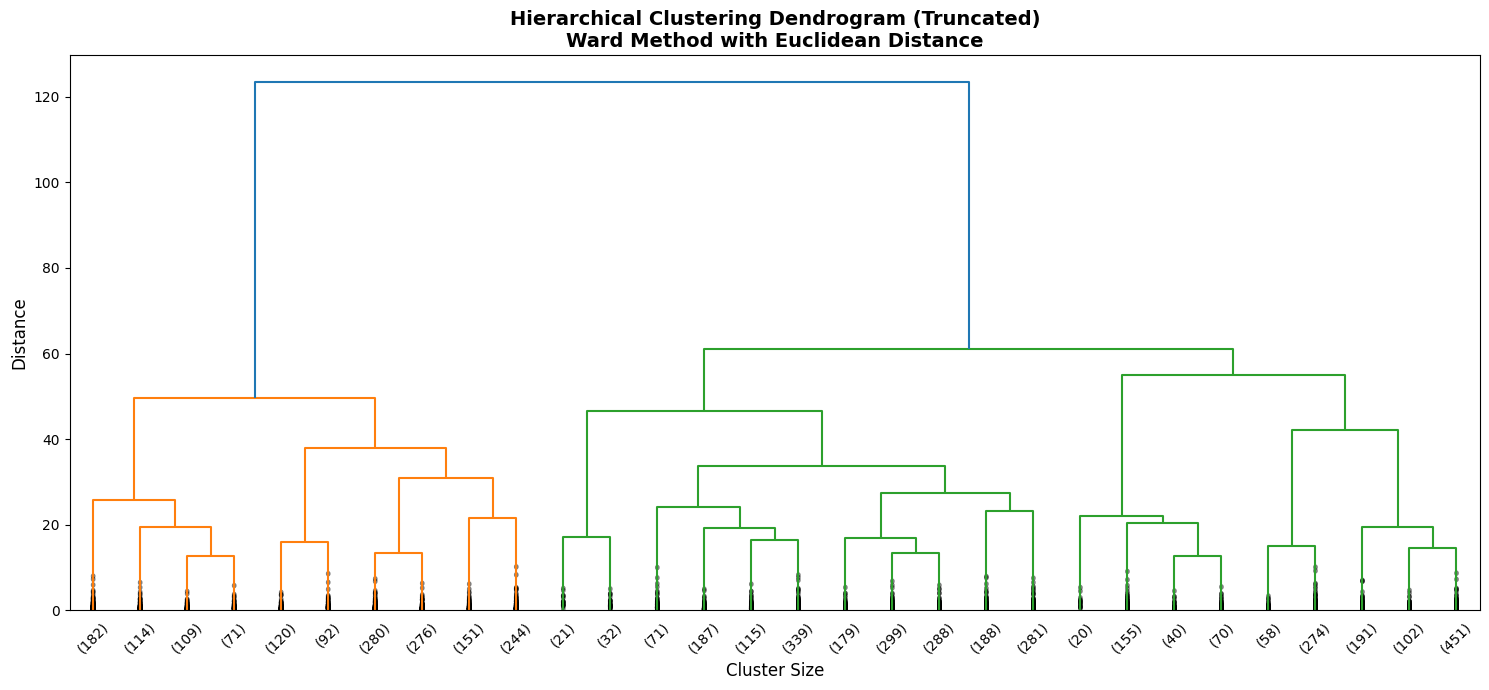

In [6]:
# Plot dendrogram
plt.figure(figsize=(15, 7))
dendrogram(linkage_matrix, 
           truncate_mode='lastp',
           p=30,
           leaf_font_size=10,
           show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram (Truncated)\nWard Method with Euclidean Distance', 
          fontsize=14, fontweight='bold')
plt.xlabel('Cluster Size', fontsize=12)
plt.ylabel('Distance', fontsize=12)
plt.tight_layout()
plt.show()


We now try agglomerative clustering for k in range from 2 to 20 in order to choose the optimal k.

k     Silhouette  
------------------------------
2     0.2955      
3     0.1734      
4     0.1758      
5     0.1643      
6     0.1714      
7     0.1770      
8     0.1681      
9     0.1430      
10    0.1441      
11    0.1435      
12    0.1469      
13    0.1511      
14    0.1475      
15    0.1498      
16    0.1485      
17    0.1522      
18    0.1449      
19    0.1453      


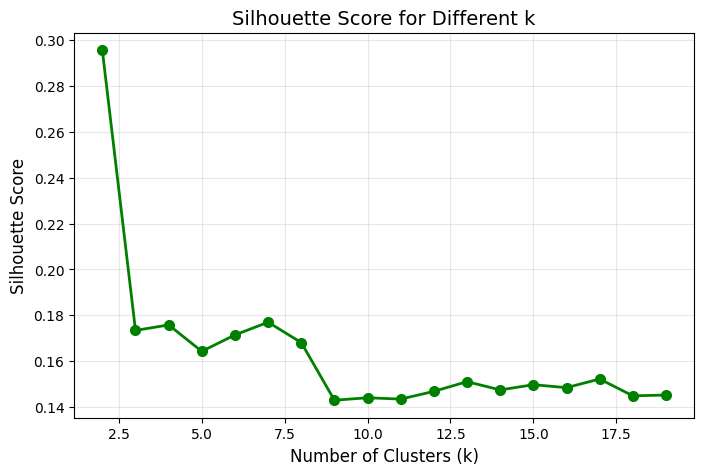

In [7]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# Range of clusters to try
cluster_range = range(2, 20)
silhouette_scores = []

print(f"{'k':<5} {'Silhouette':<12}")
print("-" * 30)

for k in cluster_range:
    model = AgglomerativeClustering(
        n_clusters=k,
        metric='euclidean',  # default, can omit
        linkage='ward'
    )
    labels = model.fit_predict(df_sample)  # use standardized continuous features
    
    # Silhouette score
    sil = silhouette_score(df_sample, labels, metric='euclidean')
    silhouette_scores.append(sil)
    
    print(f"{k:<5} {sil:<12.4f}")

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, silhouette_scores, 'o-', color='green', linewidth=2, markersize=7)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Score for Different k', fontsize=14)
plt.grid(alpha=0.3)
plt.show()

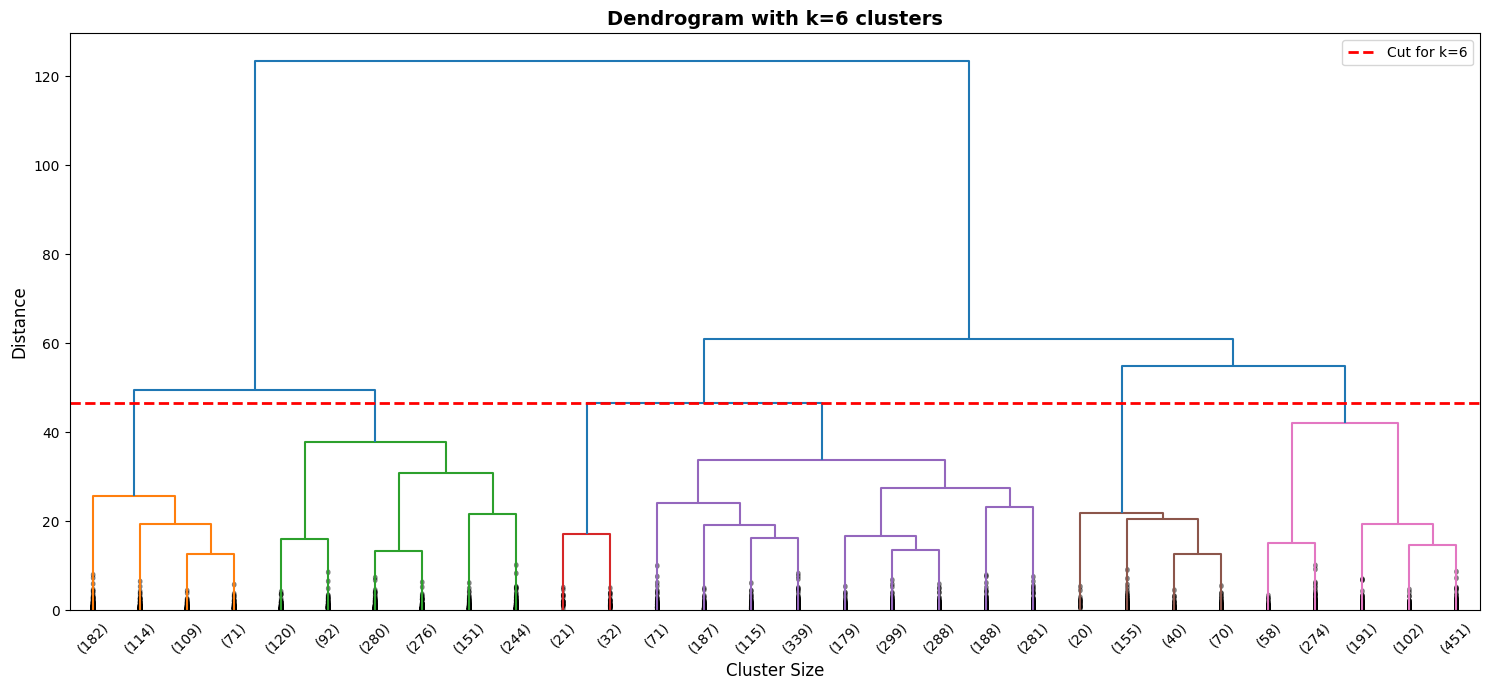

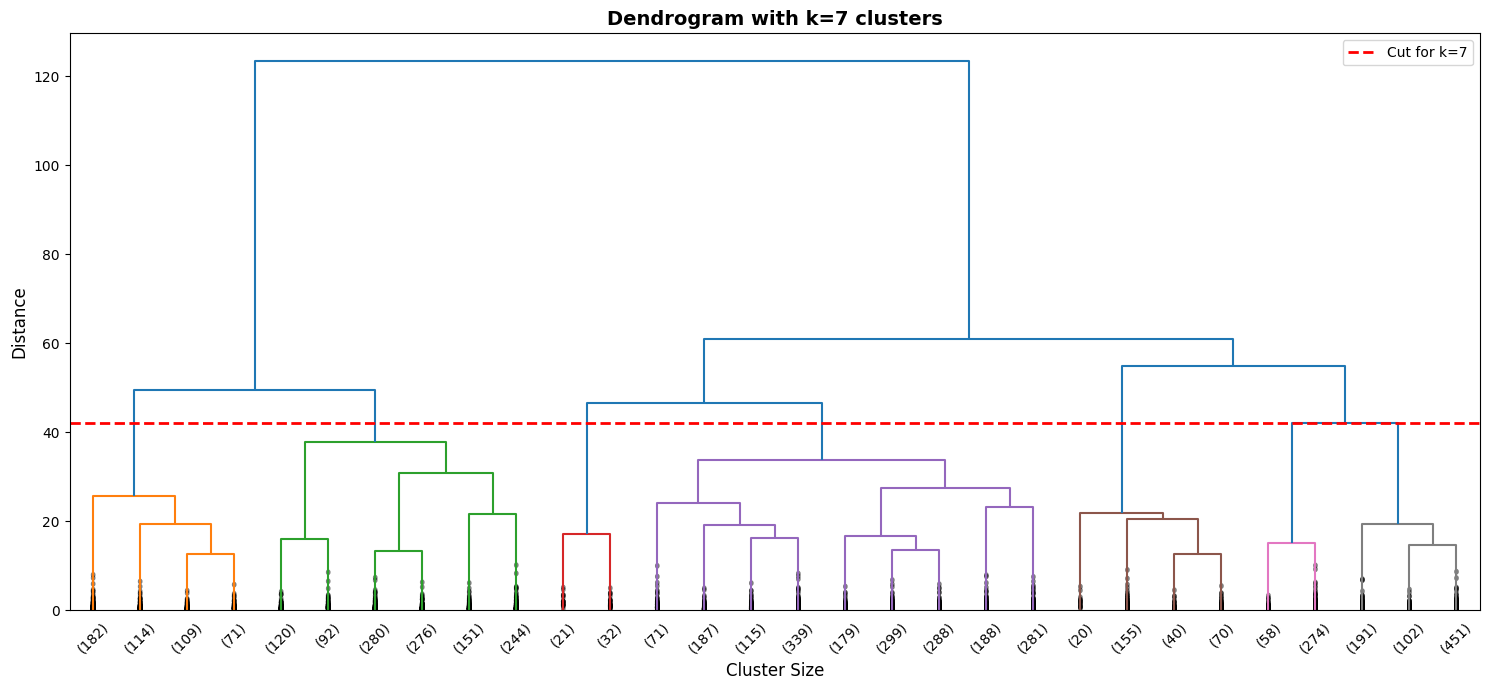

In [8]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster

# Function to plot dendrogram with clusters colored
def plot_dendrogram_k(linkage_matrix, k, title):
    plt.figure(figsize=(15, 7))
    
    # Get clusters
    clusters = fcluster(linkage_matrix, k, criterion='maxclust')
    
    # Distance threshold: just below the minimum of the last k-1 merges
    last_merges = linkage_matrix[-(k-1):, 2]
    color_threshold = last_merges.min() - 1e-5  # epsilon below min distance
    cut_distance = last_merges.min()  # where to draw horizontal line
    
    dendrogram(linkage_matrix, 
               truncate_mode='lastp',
               p=30,
               leaf_font_size=10,
               show_contracted=True,
               color_threshold=color_threshold)
    
    # Draw horizontal line at cut distance
    plt.axhline(y=cut_distance, c='red', lw=2, linestyle='--', label=f'Cut for k={k}')
    
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('Cluster Size', fontsize=12)
    plt.ylabel('Distance', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Plot dendrograms for k=6,7
plot_dendrogram_k(linkage_matrix, 6, 'Dendrogram with k=6 clusters')
plot_dendrogram_k(linkage_matrix, 7, 'Dendrogram with k=7 clusters')


Combining the information from the previous graphs, k of 6 and 7 were taken into consideration. k = 6 was found to be the best compromise between silhouette (0.17) and, most importantly, explainability of the data.

In [9]:
# Determine clusters using AgglomerativeClustering
n_clusters = 6  # Choose based on dendrogram inspection

hierarchical = AgglomerativeClustering(
    n_clusters=n_clusters,
    metric='euclidean',
    linkage='ward'
)

df_raw_sample['Cluster'] = hierarchical.fit_predict(df_sample)

print(f"Clustering complete with {n_clusters} clusters")
print(f"\nCluster distribution:")
print(df_raw_sample['Cluster'].value_counts().sort_index())


Clustering complete with 6 clusters

Cluster distribution:
Cluster
0    1076
1    1947
2    1163
3     285
4     476
5      53
Name: count, dtype: int64


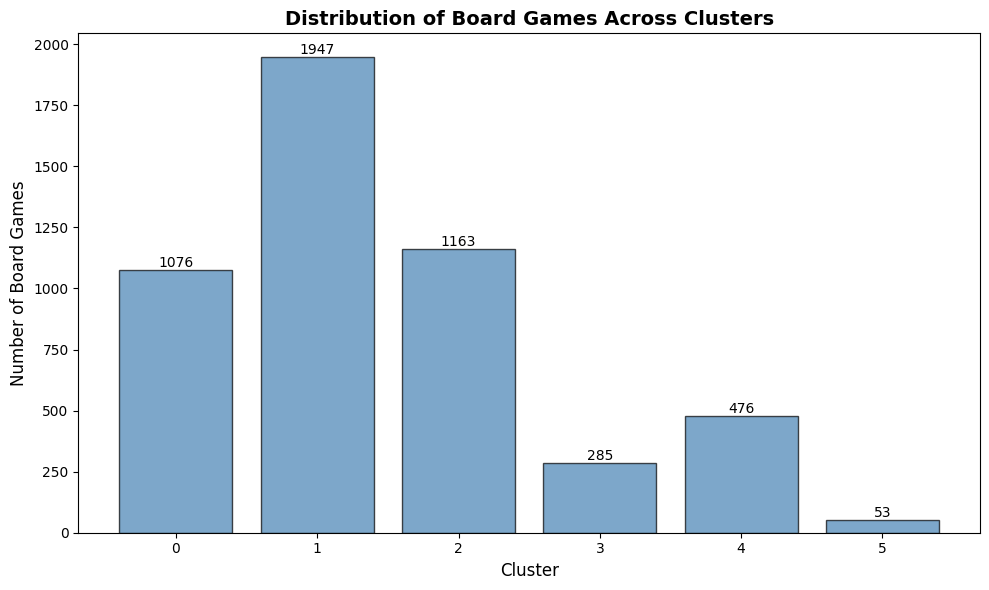

In [10]:
# %%
# Visualize cluster sizes
plt.figure(figsize=(10, 6))
cluster_counts = df_raw_sample['Cluster'].value_counts().sort_index()
bars = plt.bar(cluster_counts.index, cluster_counts.values, color='steelblue', alpha=0.7, edgecolor='black')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of Board Games', fontsize=12)
plt.title('Distribution of Board Games Across Clusters', fontsize=14, fontweight='bold')
plt.xticks(cluster_counts.index)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


Even though clustering was only done with 5 features, it's interesting to see if also other patterns show up in the other variables.

What's worthy of noting is that all of the clustering approaches tend to form the same clusters (as of game archetypes) with similar separations.

In [11]:
# Columns used in scaling
continuous_values = ['GameWeight', 'MaxPlayers_log', 'Age', 'AvgPlaytime_log', 'AgeRec']

# Additional columns
continuous_additional = ['MinPlayers', 'NumOwned', 'NumWant', 'NumAlternates', 
                         'NumExpansions', 'NumImplementations'] 
binary_additional = ['Cat:Thematic', 'Cat:Strategy', 'Cat:War', 'Cat:Family', 
                     'Cat:CGS', 'Cat:Abstract', 'Cat:Party', 'Cat:Childrens', 
                     'IsReimplementation', 'Kickstarted']

# Make a copy to avoid modifying original data
df_destandardized = df_raw_sample.copy()

# De-standardize all scaled columns at once
df_destandardized[continuous_values] = scaler.inverse_transform(
    df_raw_sample[continuous_values]
)

# Apply de-log to columns that were log-transformed and rename
final_continuous = []
for col in continuous_values:
    if col.endswith('_log'):
        df_destandardized[col] = np.expm1(df_destandardized[col])
        new_col = col.replace('_log', '')
    else:
        new_col = col
    final_continuous.append(new_col)
    df_destandardized.rename(columns={col: new_col}, inplace=True)

# Final dataframe to analyze
df_to_analyze = df_destandardized[final_continuous + continuous_additional + binary_additional + ['Cluster']]


print("=" * 60)
print("CLUSTER STATISTICS (Sample + Additional Columns)")
print("=" * 60)

for cluster_id in sorted(df_to_analyze['Cluster'].unique()):
    cluster_idx = df_to_analyze[df_to_analyze['Cluster'] == cluster_id].index
    print(f"\nCluster {cluster_id} (n={len(cluster_idx)}):")
    print("-" * 40)

    # --- Continuous Features (median) ---
    print("\nContinuous Features (median):")
    for feat in final_continuous + continuous_additional:
        # Use de-standardized value if it was scaled, otherwise raw data
        if feat in final_continuous:
            val = df_destandardized.loc[cluster_idx, feat].values
        else:
            val = df_raw_sample.loc[cluster_idx, feat].values  # raw data

        print(f"  {feat}: {np.median(val):.2f}")

    # --- Binary Features (average) ---
    if binary_additional:
        print("\nBinary Features (average):")
        for feat in binary_additional:
            val = df_raw_sample.loc[cluster_idx, feat]
            print(f"  {feat}: {val.mean():.2f}")

print("\n" + "=" * 60)



CLUSTER STATISTICS (Sample + Additional Columns)

Cluster 0 (n=1076):
----------------------------------------

Continuous Features (median):
  GameWeight: 1.20
  MaxPlayers: 4.00
  Age: 12.00
  AvgPlaytime: 20.00
  AgeRec: 7.08
  MinPlayers: 2.00
  NumOwned: 239.00
  NumWant: 5.00
  NumAlternates: 1.00
  NumExpansions: 0.00
  NumImplementations: 0.00

Binary Features (average):
  Cat:Thematic: 0.01
  Cat:Strategy: 0.02
  Cat:War: 0.01
  Cat:Family: 0.14
  Cat:CGS: 0.02
  Cat:Abstract: 0.07
  Cat:Party: 0.03
  Cat:Childrens: 0.15
  IsReimplementation: 0.12
  Kickstarted: 0.10

Cluster 1 (n=1947):
----------------------------------------

Continuous Features (median):
  GameWeight: 1.78
  MaxPlayers: 5.00
  Age: 12.00
  AvgPlaytime: 37.50
  AgeRec: 9.76
  MinPlayers: 2.00
  NumOwned: 354.00
  NumWant: 8.00
  NumAlternates: 0.00
  NumExpansions: 0.00
  NumImplementations: 0.00

Binary Features (average):
  Cat:Thematic: 0.06
  Cat:Strategy: 0.08
  Cat:War: 0.02
  Cat:Family: 0.18
  Cat:C

### Cluster 0

- 1,076 records (largest cluster)
- Age ≈ 12 years
- GameWeight ≈ 1.2 (light)
- MaxPlayers ≈ 4
- AvgPlaytime ≈ 20 mins
- NumOwned ≈ 239
- NumWant ≈ 5
- Minimal expansions, alternates, and implementations
- Low Kickstarter presence (10%)

Light, family- and children-oriented games. This cluster represents accessible, quick-play titles suitable for younger audiences, with moderate ownership but limited ongoing demand or additional content. The low strategy/war presence suggests these are mostly casual games rather than hobbyist-focused titles.

### Cluster 1

- 1,947 records
- Age ≈ 12 years
- GameWeight ≈ 1.78 (light-medium)
- MaxPlayers ≈ 5
- AvgPlaytime ≈ 37.5 mins
- NumOwned ≈ 354
- NumWant ≈ 8
- Minimal expansions and alternates
- Moderate Kickstarter presence (17%)

Casual hobbyist games with slightly higher complexity. This cluster includes games appealing to both families and strategy players, with moderate popularity and some interest in crowdfunding, indicating newer or trending titles in light strategy and thematic categories.

### Cluster 2

- 1,163 records
- Age ≈ 11 years
- GameWeight ≈ 2.8 (medium-heavy)
- MaxPlayers ≈ 4
- AvgPlaytime ≈ 90 mins
- NumOwned ≈ 516
- NumWant ≈ 27
- Minimal expansions/alternates/implementations
- Strong Kickstarter presence (25%)
- High strategy and war representation

Dedicated hobbyist and wargaming titles. This cluster represents deep, engaging games with significant gameplay complexity, high ownership among enthusiasts, and substantial ongoing demand. Crowdfunding plays a notable role, highlighting modern publishing trends in strategy and war genres.

### Cluster 3

- 285 records (smallest cluster)
- Age ≈ 45 years
- GameWeight ≈ 1.41 (light)
- MaxPlayers ≈ 4
- AvgPlaytime ≈ 30 mins
- NumOwned ≈ 227
- NumWant ≈ 5
- Minimal expansions and alternates
- Very low Kickstarter presence (1%)

Older, abstract/child-focused titles. This cluster captures mid-complexity games from previous decades that have endured, primarily in family or abstract categories. Despite age, ownership is steady, reflecting nostalgic or classic appeal rather than current trends.

### Cluster 4

- 476 records
- Age ≈ 37 years
- GameWeight ≈ 2.71 (medium-heavy)
- MaxPlayers ≈ 2
- AvgPlaytime ≈ 120 mins
- NumOwned ≈ 349
- NumWant ≈ 11
- Minimal expansions and alternates
- Low Kickstarter presence (0%)

Classic heavy war games. This cluster consists of mature, two-player-focused titles with long playtimes and a strong war strategy presence. These represent historically significant designs that maintain a dedicated, niche audience but are rarely expanded or crowdfunded.

### Cluster 5

- 53 records (tiny cluster)
- Age ≈ 14 years
- GameWeight ≈ 1.75 (light-medium)
- MaxPlayers ≈ 99 (party-oriented)
- AvgPlaytime ≈ 40 mins
- NumOwned ≈ 278
- NumWant ≈ 7
- Some party and war elements
- Moderate Kickstarter presence (11%)

Party and large-group games. This cluster captures games designed for large groups or social events, often with unique mechanics or thematic quirks. Ownership is modest, and these are occasionally crowdfunded, reflecting niche social gaming experiences rather than core strategy or hobbyist focus.


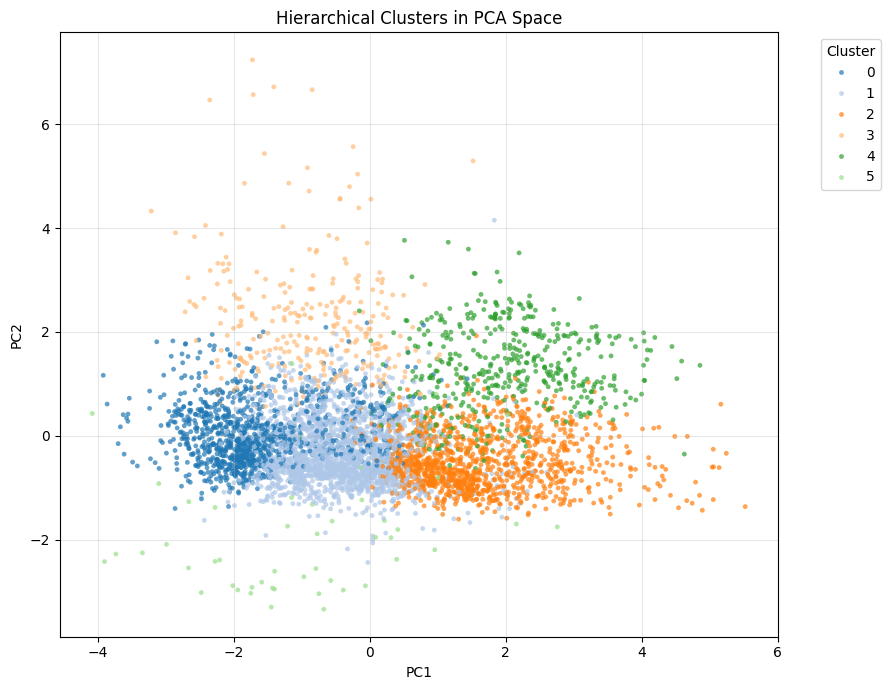

Explained variance by PC1 and PC2: [0.497 0.202]


In [12]:
# PCA visualization
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_raw_sample[continuous_values])

df_plot = df_raw_sample[continuous_values+['Cluster']].copy()
df_plot["PC1"] = X_pca[:, 0]
df_plot["PC2"] = X_pca[:, 1]

palette = sns.color_palette("tab20", n_colors=df_plot["Cluster"].nunique())

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_plot,
    x="PC1", y="PC2",
    hue="Cluster",
    palette=palette,
    s=12, alpha=0.7, linewidth=0
)
plt.title("Hierarchical Clusters in PCA Space")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Explained variance by PC1 and PC2:",
      np.round(pca.explained_variance_ratio_, 3))


Graphs reported below show info on the rating variable and how it's distributed between the clusters

<Figure size 900x500 with 0 Axes>

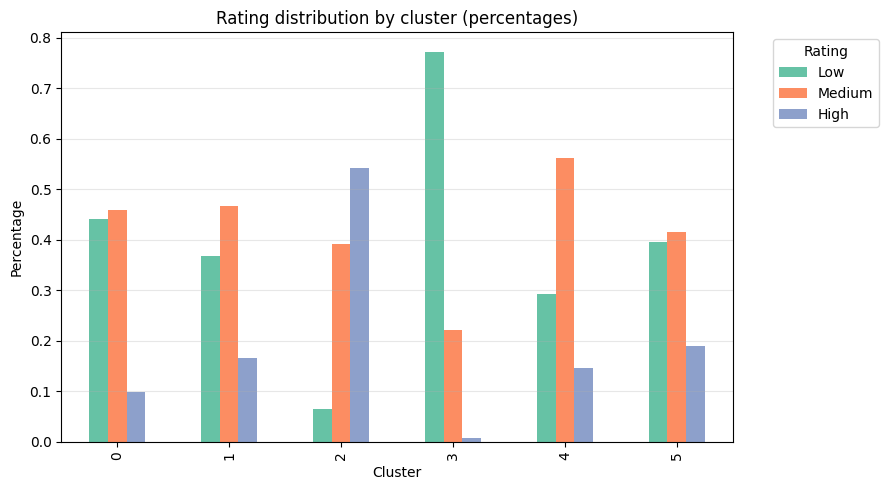

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

rating_proportions = (
    df_raw_sample.groupby("Cluster")["Rating"]
       .value_counts(normalize=True)
       .unstack(fill_value=0)
       .round(3)
)

rating_order = ['Low', 'Medium', 'High']
rating_proportions = rating_proportions[[col for col in rating_order if col in rating_proportions.columns]]

plt.figure(figsize=(9, 5))

rating_proportions.plot(kind='bar', figsize=(9, 5), color=sns.color_palette("Set2"))
plt.title("Rating distribution by cluster (percentages)")
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



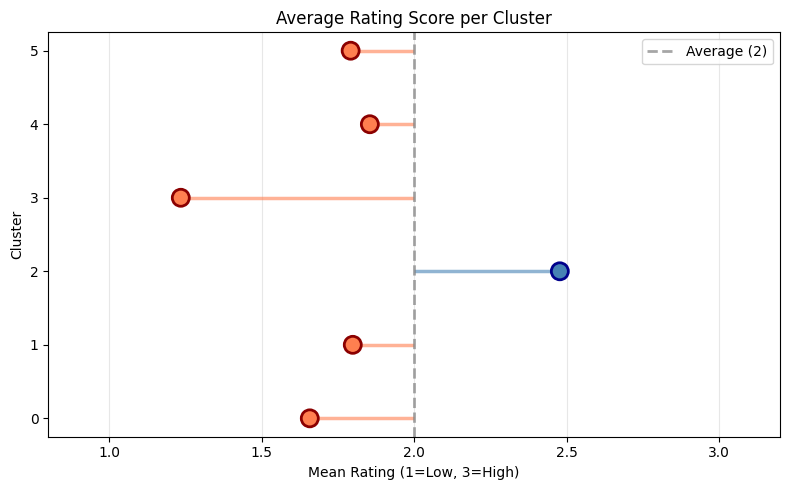

In [14]:
import matplotlib.pyplot as plt

rating_map = {"Low": 1, "Medium": 2, "High": 3}

df_raw_sample["Rating_num"] = df_raw_sample["Rating"].map(rating_map)

mean_rating_per_cluster = (
    df_raw_sample.groupby("Cluster")["Rating_num"]
       .mean()
       .round(3)
)

plt.figure(figsize=(8, 5))

# Calcola quali cluster sono sopra/sotto la media di 2
colors = ['steelblue' if x > 2 else 'coral' for x in mean_rating_per_cluster.values]
edge_colors = ['darkblue' if x > 2 else 'darkred' for x in mean_rating_per_cluster.values]

# Linee orizzontali - partono da 2 (la media)
for i, (idx, val) in enumerate(mean_rating_per_cluster.items()):
    if val > 2:
        # Sopra la media: va a destra
        plt.hlines(y=i, xmin=2, xmax=val, color='steelblue', alpha=0.6, linewidth=2.5)
    else:
        # Sotto la media: va a sinistra
        plt.hlines(y=i, xmin=val, xmax=2, color='coral', alpha=0.6, linewidth=2.5)

# Punti alla fine delle linee
plt.scatter(
    mean_rating_per_cluster.values, 
    range(len(mean_rating_per_cluster)), 
    s=150, 
    c=colors,
    edgecolors=edge_colors,
    linewidth=2,
    zorder=3
)

# Configurazione assi e labels
plt.yticks(range(len(mean_rating_per_cluster)), mean_rating_per_cluster.index)
plt.xlim(0.8, 3.2)
plt.xlabel("Mean Rating (1=Low, 3=High)")
plt.ylabel("Cluster")
plt.title("Average Rating Score per Cluster")

# Linea verticale per la media a 2
plt.axvline(x=2, color='gray', linestyle='--', alpha=0.7, linewidth=2, label='Average (2)')

plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()